<a href="https://colab.research.google.com/github/Rahul-Garg2006/DNN_Project/blob/main/defect_dataset_builder_v6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 3D print defect dataset builder v5 (3 datasets -> 1 merged dataset)

**What changed from v4:** this version merges **three** datasets instead of two.
1. **Roboflow** "Defects Classification in 3D Printing" (`defcls`) - downloaded with your API key (same as before).
2. **Bast et al.** (`bast`) - sampled from Zenodo, but this time **only the extrusion class is kept** (you asked for "only the extrusion classes from Bast"). Its `good` and `layer_shift` folders are not downloaded.
3. **Kaggle** "3D printing errors" by nimbus200 (`d3d`) - the new third dataset.

Everything else works like v4: it shows you the class names, you map them to one shared list, it removes duplicates, splits into train / val / test keeping copies of a photo together, and saves `merged_dataset.zip` in your Google Drive. **Your existing training notebook reads that same zip, so you do not need to change it.**

**How to use it:** run the cells from top to bottom, one at a time. The cells marked **YOU MAY EDIT THIS** are the only ones you touch. You do **not** need a GPU for this notebook.

## Step 1: Connect Google Drive and set the folders
A popup will ask for permission to use your Google Drive. Click **Connect to Google Drive** and then **Allow**.
- **Google Drive** (`defect_project` folder): permanent. The final merged dataset is saved here.
- **Colab disk** (`/content/work`): fast but temporary. It is wiped when the Colab session ends, so in a new session just run the steps again (they are quick) or use the zip saved in Drive.

In [ ]:
import os, re, csv, shutil, hashlib, zipfile, collections
from pathlib import Path

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab, skipping the Drive mount.')

DRIVE = Path(os.environ.get('DEFECT_DRIVE', '/content/drive/MyDrive/defect_project'))
WORK  = Path(os.environ.get('DEFECT_WORK',  '/content/work'))
RAW   = WORK / 'raw'        # downloaded datasets, one folder each
STAGE = WORK / 'staging'    # renamed copies, one folder per class (rebuilt every run)
OUT   = WORK / 'merged'     # final train/val/test folders (rebuilt every run)

for p in (DRIVE, RAW):
    p.mkdir(parents=True, exist_ok=True)

DATASETS = ['defcls', 'bast', 'd3d']   # folder names inside RAW. defcls=Roboflow, bast=Bast, d3d=Kaggle
print('Google Drive folder :', DRIVE)
print('Working folder      :', WORK)

Mounted at /content/drive
Google Drive folder : /content/drive/MyDrive/defect_project
Working folder      : /content/work


## Step 2: Download dataset 1 from Roboflow  (same as v4)
- You need your Roboflow **API key** (Settings in your Roboflow account). When you run the cell, paste it into the small hidden box and press Enter. It is not saved in the notebook. Never share it.
- If you get a **version not found** error, change `ROBOFLOW_VERSION` below (on the dataset page click *Download Dataset*, choose *Folder Structure*, then *Show download code*, and copy the version number).
- It takes about a minute.

In [ ]:
%pip install -q roboflow
from getpass import getpass
from roboflow import Roboflow

ROBOFLOW_WORKSPACE = 'project-jkfnh'
ROBOFLOW_PROJECT   = 'defects-classification-in-3d-printing-fwsu3'
ROBOFLOW_VERSION   = 1          # <- change this if you get a "version not found" error

dest = RAW / 'defcls'
if dest.exists() and len(list(dest.rglob('*.*'))) > 10:
    print('Already downloaded:', dest)
else:
    key = getpass('Paste your Roboflow API key here and press Enter: ')
    rf = Roboflow(api_key=key)
    project = rf.workspace(ROBOFLOW_WORKSPACE).project(ROBOFLOW_PROJECT)
    project.version(ROBOFLOW_VERSION).download('folder', location=str(dest))
    print('Downloaded to', dest)

Paste your Roboflow API key here and press Enter: ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/work/raw/defcls in folder:: 100%|██████████| 11235/11235 [00:01<00:00, 5798.06it/s]

Downloaded to /content/work/raw/defcls


## Step 3: Download ONLY the extrusion class of dataset 2 (Bast et al.) from Zenodo
Same sampling idea as v4, but `BAST_KEEP` below limits it to the **extrusion** class only, so it downloads about a third as many files and you do not waste time on Bast's `good` and `layer_shift` images (those classes already come from Roboflow).

`base_data.zip` is used for training and validation. `test_data.zip` (the authors' separate test set) is used only for the test set. The progress bar shows how it is going; if it is too slow, stop it, lower the two numbers, and run again (it skips files it already has).

In [ ]:
%pip install -q remotezip
import random, time, threading
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm.auto import tqdm
from remotezip import RemoteZip

# Keep ONLY these Bast class folders. To bring back a Bast class, add its folder name here
# (the Bast folders are: extrusion_error_print, layershift_error_print, no_error_print).
BAST_KEEP = {'extrusion_error_print'}

BAST = {
    'base_data': dict(url='https://zenodo.org/records/14712897/files/base_data.zip?download=1', per_class=700),
    'test_data': dict(url='https://zenodo.org/records/14712897/files/test_data.zip?download=1', per_class=250),
}
WORKERS = 6      # how many files are downloaded at the same time
SEED = 42
bast_root = RAW / 'bast'

def class_and_camera(name):
    # path looks like  base/cropped/<class>/<camera>/<file>.jpg
    parts = Path(name).parts
    i = [p.lower() for p in parts].index('cropped')
    cls = parts[i + 1]
    cam = parts[i + 2] if len(parts) > i + 3 else 'none'
    return cls, cam

def pick_files(url, per_class):
    with RemoteZip(url) as z:
        names = [i.filename for i in z.infolist() if not i.is_dir() and '/cropped/' in i.filename.replace('\\', '/')]
    groups = collections.defaultdict(list)
    for n in names:
        groups[class_and_camera(n)].append(n)
    rnd = random.Random(SEED)
    chosen = []
    for c in sorted({c for c, _ in groups}):
        if BAST_KEEP and c not in BAST_KEEP:      # skip the Bast classes we are not keeping
            continue
        cams = sorted(cam for cc, cam in groups if cc == c)
        quota = per_class // len(cams)
        got, avail = 0, 0
        for cam in cams:
            ns = sorted(groups[(c, cam)])
            k = min(quota, len(ns))
            chosen += rnd.sample(ns, k)
            got += k
            avail += len(ns)
        print(f'    {c}: {avail} available, taking {got} (from {len(cams)} cameras)')
    return chosen

_tl = threading.local()
def fetch_one(url, name):
    out = bast_root / name
    if out.exists() and out.stat().st_size > 0:
        return True
    for attempt in range(5):
        try:
            if not hasattr(_tl, 'zips'):
                _tl.zips = {}
            if url not in _tl.zips:
                _tl.zips[url] = RemoteZip(url)
            _tl.zips[url].extract(name, path=str(bast_root))
            return True
        except Exception:
            _tl.zips = {}          # reconnect on the next try
            time.sleep(2 * (attempt + 1))
    return False

def run_jobs(job_list, workers, label):
    bad = []
    with ThreadPoolExecutor(workers) as ex:
        futs = {ex.submit(fetch_one, u, n): (u, n) for u, n in job_list}
        for f in tqdm(as_completed(futs), total=len(futs), desc=label):
            if not f.result():
                bad.append(futs[f])
    return bad

jobs = []
for tag, cfg in BAST.items():
    print(f'{tag}: reading the file list ...')
    for n in pick_files(cfg['url'], cfg['per_class']):
        jobs.append((cfg['url'], n))
print(f'Downloading {len(jobs)} files with {WORKERS} workers ...')

failed = run_jobs(jobs, WORKERS, 'downloading')
if failed:
    print(f'{len(failed)} downloads failed. Trying those again, more slowly ...')
    failed = run_jobs(failed, 2, 'retrying')
print(f'Done. Failed downloads: {len(failed)} of {len(jobs)}')

base_data: reading the file list ...
    extrusion_error_print: 14866 available, taking 699 (from 3 cameras)
test_data: reading the file list ...
    extrusion_error_print: 7006 available, taking 249 (from 3 cameras)


downloading:   0%|          | 0/948 [00:00<?, ?it/s]

5 downloads failed. Trying those again, more slowly ...


retrying:   0%|          | 0/5 [00:00<?, ?it/s]

Done. Failed downloads: 0 of 948


## Step 4: Download dataset 3 (Kaggle "3D printing errors") - NEW
This downloads `nimbus200/3d-printing-errors` from Kaggle. Kaggle needs a small key file called `kaggle.json`:

1. Go to **kaggle.com**, sign in, click your **profile picture** (top right) -> **Settings**.
2. Scroll to the **API** section and click **Create New Token**. A file `kaggle.json` downloads to your computer.
3. **Also open the dataset page once** (kaggle.com/datasets/nimbus200/3d-printing-errors) while signed in, so your account has accepted it.
4. Run the cell below. When it asks, click **Choose Files** and pick the `kaggle.json` you just downloaded.

It downloads and unzips into `raw/d3d`. You only do the upload once per Colab session.

In [ ]:
%pip install -q kaggle
import subprocess

KAGGLE_DATASET = 'nimbus200/3d-printing-errors'   # the "3D printing errors" dataset
dest = RAW / 'd3d'

if dest.exists() and len(list(dest.rglob('*.*'))) > 10:
    print('Already downloaded:', dest)
else:
    kpath = Path.home() / '.kaggle' / 'kaggle.json'
    if not kpath.exists():
        from google.colab import files
        print('Upload your kaggle.json (Kaggle -> profile picture -> Settings -> API -> Create New Token):')
        up = files.upload()
        jname = [k for k in up if k.endswith('.json')][0]
        kpath.parent.mkdir(parents=True, exist_ok=True)
        kpath.write_bytes(up[jname])
    os.chmod(kpath, 0o600)
    dest.mkdir(parents=True, exist_ok=True)
    print('Downloading from Kaggle ...')
    r = subprocess.run(['kaggle', 'datasets', 'download', '-d', KAGGLE_DATASET, '-p', str(dest), '--unzip'],
                       capture_output=True, text=True)
    print(r.stdout[-1500:]); print(r.stderr[-1500:])
    n = len(list(dest.rglob('*.*')))
    print('Files now in', dest, ':', n)
    assert n > 0, 'Download failed. Check kaggle.json, and open the dataset page on Kaggle once while signed in.'

Upload your kaggle.json (Kaggle -> profile picture -> Settings -> API -> Create New Token):


## Step 5: Look inside all three datasets (this cell only reads, it changes nothing)
It prints every folder that contains images and how many images are in it, for each dataset. **Copy the printed text and send it to me**, especially the `d3d` part, so we set its class names right in Step 6.

In [ ]:
from PIL import Image

IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}
SPLIT_NAMES = {'train', 'val', 'valid', 'validation', 'test'}

def norm(s):
    # 'Blobs and Zits' -> 'blobs_and_zits' (the form used as keys in LABEL_MAP below)
    return re.sub(r'[^a-z0-9]+', '_', str(s).lower()).strip('_')

def summarize(root, max_lines=70):
    imgs = [p for p in root.rglob('*') if p.suffix.lower() in IMG_EXT]
    counts = collections.Counter(str(p.parent.relative_to(root)) for p in imgs)
    print(f'  total images: {len(imgs)}')
    lines = sorted(counts.items())
    for d, n in lines[:max_lines]:
        print(f'  {n:6d}  {d}')
    if len(lines) > max_lines:
        print(f'  ... and {len(lines) - max_lines} more folders')
    print('  example file names:', [p.name for p in sorted(imgs)[:3]])

import pandas as _pd
for ds in DATASETS:
    print(f'\n=== {ds} ===')
    if not (RAW / ds).exists():
        print('  folder missing (did the earlier step run?)')
        continue
    summarize(RAW / ds)

# Kaggle (d3d) is labelled by a CSV, not by folders. sep=None lets pandas detect the
# separator (this dataset uses ';'). Show each CSV's columns and small-value columns.
for csvp in sorted((RAW / 'd3d').rglob('*.csv')) if (RAW / 'd3d').exists() else []:
    try:
        _m = _pd.read_csv(csvp, sep=None, engine='python', on_bad_lines='skip')
        print(f'\n  --- CSV {csvp.name}: {len(_m)} rows, columns = {list(_m.columns)} ---')
        for col in _m.columns:
            if 2 <= _m[col].nunique() <= 12:
                print(f'    {col}:', _m[col].value_counts().to_dict())
    except Exception as e:
        print('  could not read', csvp, e)


=== defcls ===
  total images: 11233
     119  test/Bed Adhesion
     104  test/Blob of Death
      95  test/Blobs and Zits
      95  test/Layer Separation
     104  test/Layer Shifting
      94  test/No Defect
     105  test/Nozzle Clog
      41  test/Over Extrusion
      93  test/Spaghetti
      95  test/Stringing
      95  test/Under Extrusion
      94  test/Warping
     864  train/Bed Adhesion
     792  train/Blob of Death
     903  train/Blobs and Zits
     800  train/Layer Separation
     867  train/Layer Shifting
     828  train/No Defect
     891  train/Nozzle Clog
     810  train/Over Extrusion
     821  train/Spaghetti
     853  train/Stringing
     831  train/Under Extrusion
     839  train/Warping
  example file names: ['-2025-07-23-150034_jpg.rf.958f44ac48524cae992db7e321b3deff.jpg', '-2025-07-23-150045_jpg.rf.2e27c7d146a3efe13b6a371ff568ccfc.jpg', '-2025-07-23-150057_jpg.rf.dc5bd7b8c39fdc7aaa3afabde72e335d.jpg']

=== bast ===
  total images: 948
     233  base/cropped/ex

## Step 6: Class names and settings  (YOU MAY EDIT THIS)
Two datasets are labelled by folder names, and one (Kaggle) by a CSV. Both are set up for you below.

- **`defcls` (Roboflow)**: all 12 classes kept, same as v4.
- **`bast`**: only `extrusion_error_print` -> `extrusion_error`. (The other two are `None`, and Step 3 did not download them anyway.)
- **`d3d` (Kaggle)**: labelled by its CSV `class` column, using the numbers from the dataset's own description: **0 = Good, 1 = Under-Extrusion, 2 = Stringing, 4 = Spaghetti**. All four already exist in Roboflow, so they merge into the same classes - these become your strongest classes (two sources each). If Step 5 showed a different CSV column name, change `D3D_CSV_*` below.
- **`MAX_PER_CLASS`**: caps how many images any one class may have, so the big Kaggle classes (Good ~5000) do not swamp the small ones. Spaghetti (~134) stays as-is. Lower or raise it if you want.

In [ ]:
LABEL_MAP = {
    'defcls': {
        'no_defect':         'good',
        'blobs_and_zits':    'blobs_zits',
        'layer_separation':  'layer_separation',
        'layer_shifting':    'layer_shift',
        'over_extrusion':    'over_extrusion',
        'under_extrusion':   'under_extrusion',
        'stringing':         'stringing',
        'warping':           'warping',
        'z_banding':         'z_banding',
        'spaghetti':         'spaghetti',
        'nozzle_clog':       'nozzle_clog',
        'bed_adhesion':      'bed_adhesion',
        'blob_of_death':     'blob_of_death',
        'unlabeled':         None,
    },
    'bast': {
        'extrusion_error_print':  'extrusion_error',   # the only Bast class we keep
        'layershift_error_print': None,                # dropped (layer_shift comes from Roboflow)
        'no_error_print':         None,                # dropped (good comes from Roboflow)
    },
    # 'd3d' is handled by the CSV settings below, not here.
}

# ---- Dataset 3 (Kaggle) is labelled by a CSV, not by folders ----
D3D_CSV_SEP       = ';'            # this dataset's CSV uses semicolons, not commas
D3D_CSV_PREFER    = 'no_filter'    # of the several CSVs, use the one whose name contains this
D3D_CSV_CLASS_COL = 'class'        # CSV column holding the class number
D3D_CSV_IMAGE_COL = 'image'        # CSV column holding the image file name
D3D_CSV_GROUP_COL = 'recording'    # frames from one recording stay together in one split (stops leakage)
D3D_TEST_FOLDER_SUBSTR = 'test_images'   # d3d images under a folder with this in its path go to the TEST split
D3D_CODE_TO_CLASS = {              # class number -> merged class name (from the dataset's description)
    0: 'good',
    1: 'under_extrusion',
    2: 'stringing',
    4: 'spaghetti',
    # any class number not listed here is left out
}

# ---- Balancing ----
MAX_PER_CLASS = 1000    # keep at most this many images per class (set to None to keep all)

CLASS_LEVEL = {'bast': 2}                       # Bast class = 3rd folder level inside the dataset folder
INCLUDE_IF_PATH_CONTAINS = {'bast': ['cropped']}
EXCLUDE_IF_PATH_CONTAINS = {}
GROUP_REGEX = {}

# images of these datasets whose path starts with this text always go to the TEST split
AUTHORS_TEST_PREFIX = {'bast': 'test/'}

# Step 7 compares the datasets for look-alike images. Set to True to remove the copies found in a later dataset.
DROP_CROSS_DATASET_DUPLICATES = False

## Step 7: Build the merged dataset
This copies every image you kept into one place, with the new class names. It also skips exact duplicate files (even across datasets), fingerprints each image to warn when the **same photo appears in more than one dataset**, and keeps Roboflow's augmented copies of a photo together with the original.

At the end it prints what it skipped and any class names it could not map. If you see an **UNMAPPED** list, go back to Step 6, add those names, and run Step 7 again.

In [ ]:
import pandas as pd

def get_class(ds, root, p):
    rel = p.relative_to(root).parts[:-1]          # folder names between the dataset root and the image
    lvl = CLASS_LEVEL.get(ds)
    if lvl is not None:
        return rel[lvl] if len(rel) > lvl else None
    c = p.parent.name
    if norm(c) in SPLIT_NAMES:
        c = p.parent.parent.name
    return c

def safe(s):
    return re.sub(r'[^A-Za-z0-9_.-]+', '_', s)[:80]

def md5(p):
    h = hashlib.md5()
    with open(p, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()

RESAMPLE = Image.Resampling.LANCZOS if hasattr(Image, 'Resampling') else Image.LANCZOS

def dhash(im, size=8):
    # tiny 64-bit fingerprint: similar-looking images get the same (or nearly the same) value
    g = im.convert('L').resize((size + 1, size), RESAMPLE)
    px = list(g.getdata())
    bits = 0
    for r in range(size):
        for c in range(size):
            a, b = px[r * (size + 1) + c], px[r * (size + 1) + c + 1]
            bits = (bits << 1) | (1 if a > b else 0)
    return f'{bits:016x}'

def group_of(ds, src_class, stem):
    base = stem.split('.rf.')[0]                  # drop Roboflow's augmentation suffix
    rx = GROUP_REGEX.get(ds)
    if rx:
        m = re.match(rx, base)
        if m:
            base = m.group(1)
    return f'{ds}:{norm(src_class)}:{base}'

if STAGE.exists():
    shutil.rmtree(STAGE)
rows, seen_md5 = [], set()
skipped, unmapped = collections.Counter(), collections.Counter()

def process_d3d(root):
    # Kaggle set: labels live in a CSV (semicolon-separated), images are referenced by file name.
    csvs = sorted(root.rglob('*.csv'), key=lambda p: -p.stat().st_size)
    if not csvs:
        print('[d3d] no CSV found, skipped'); return
    pref = [c for c in csvs if D3D_CSV_PREFER.lower() in c.name.lower()]
    csvp = pref[0] if pref else csvs[0]
    meta = pd.read_csv(csvp, sep=D3D_CSV_SEP, engine='python', on_bad_lines='skip')
    print(f'[d3d] reading labels from {csvp.name} ({len(meta)} rows, columns {list(meta.columns)[:4]}...)')
    for col in (D3D_CSV_CLASS_COL, D3D_CSV_IMAGE_COL):
        if col not in meta.columns:
            print(f'[d3d] column {col!r} not in CSV {list(meta.columns)} - fix D3D_CSV_* in Step 6'); return
    index = {}                                    # file name -> path, so CSV rows find their image
    for p in root.rglob('*'):
        if p.suffix.lower() in IMG_EXT:
            index.setdefault(p.name, p); index.setdefault(p.stem, p)
    has_group = D3D_CSV_GROUP_COL in meta.columns
    by_folder = collections.Counter()
    for _, r in meta.iterrows():
        nm = str(r[D3D_CSV_IMAGE_COL])
        p = index.get(nm) or index.get(Path(nm).name) or index.get(Path(nm).stem)
        if p is None:
            skipped['d3d_image_not_found'] += 1; continue
        try:
            code = int(float(r[D3D_CSV_CLASS_COL]))
        except Exception:
            skipped['d3d_bad_class'] += 1; continue
        tgt = D3D_CODE_TO_CLASS.get(code)
        if tgt is None:
            skipped['d3d_dropped_class'] += 1; continue
        h = md5(p)
        if h in seen_md5:
            skipped['exact_duplicate'] += 1; continue
        seen_md5.add(h)
        try:
            with Image.open(p) as im:
                dh = dhash(im)
        except Exception:
            skipped['unreadable_image'] += 1; continue
        grp = str(r[D3D_CSV_GROUP_COL]) if has_group else p.stem
        rel = p.relative_to(root).as_posix()
        by_folder[p.parent.name] += 1
        out = STAGE / tgt / f'd3d__{safe(p.stem)}__{h[:6]}{p.suffix.lower()}'
        out.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(p, out)
        rows.append(dict(path=str(out), cls=tgt, dataset='d3d', src=rel,
                         group=f'd3d:{tgt}:{grp}', dhash=dh))
    print('[d3d] labelled images per source folder:', dict(by_folder))

for ds in DATASETS:
    root = RAW / ds
    if not root.exists():
        print(f'[{ds}] folder missing, skipped')
        continue
    if ds == 'd3d':
        process_d3d(root)
        continue
    cmap = LABEL_MAP.get(ds, {})
    inc = [s.lower() for s in INCLUDE_IF_PATH_CONTAINS.get(ds, [])]
    exc = [s.lower() for s in EXCLUDE_IF_PATH_CONTAINS.get(ds, [])]
    for p in sorted(root.rglob('*')):
        if p.suffix.lower() not in IMG_EXT:
            continue
        rel = p.relative_to(root).as_posix()
        if (inc and not any(s in rel.lower() for s in inc)) or any(s in rel.lower() for s in exc):
            skipped['path_filter'] += 1
            continue
        src = get_class(ds, root, p)
        if src is None:
            skipped['no_class_folder'] += 1
            continue
        tgt = cmap.get(norm(src), '__unmapped__')
        if tgt == '__unmapped__':
            unmapped[(ds, src)] += 1
            continue
        if tgt is None:
            skipped['dropped_class'] += 1
            continue
        h = md5(p)
        if h in seen_md5:
            skipped['exact_duplicate'] += 1
            continue
        seen_md5.add(h)
        try:
            with Image.open(p) as im:
                dh = dhash(im)
        except Exception:
            skipped['unreadable_image'] += 1
            continue
        out = STAGE / tgt / f'{ds}__{safe(p.stem)}__{h[:6]}{p.suffix.lower()}'
        out.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(p, out)
        # group id includes the image's folder, so two files that share a name in different
        # folders (e.g. Bast base/ and test/) never collapse into one group and split across sets.
        grp = f'{group_of(ds, src, p.stem)}|{p.parent.relative_to(root).as_posix()}'
        rows.append(dict(path=str(out), cls=tgt, dataset=ds, src=rel, group=grp, dhash=dh))

df = pd.DataFrame(rows)
print(f'Kept {len(df)} images.  Skipped: {dict(skipped)}')
if unmapped:
    print('\nUNMAPPED (not in LABEL_MAP, so skipped). Add each one to LABEL_MAP, or map it to None to leave it out on purpose:')
    for (ds, src), n in unmapped.items():
        print(f'  {ds}: {src!r}  (key {norm(src)!r})  x{n}')
assert len(df) > 0, 'No images were kept. Check LABEL_MAP and the Step 5 output.'

# look-alike images that appear in more than one dataset
order = {d: i for i, d in enumerate(DATASETS)}
df['_o'] = df['dataset'].map(order)
per_hash = df.groupby('dhash')['dataset'].nunique()
cross = per_hash[per_hash > 1].index
print(f'\nImages with a look-alike in another dataset: {int(df["dhash"].isin(cross).sum())} '
      f'({len(cross)} fingerprints). Set DROP_CROSS_DATASET_DUPLICATES = True in Step 6 if this is a large share.')
if DROP_CROSS_DATASET_DUPLICATES and len(cross):
    first = df[df['dhash'].isin(cross)].groupby('dhash')['_o'].min()
    drop = df['dhash'].isin(cross) & (df['_o'] > df['dhash'].map(first))
    print(f'Removing {int(drop.sum())} look-alike images from the later dataset.')
    df = df[~drop]
df = df.drop(columns=['_o']).reset_index(drop=True)

# cap each class so the big Kaggle classes don't swamp the small ones
if MAX_PER_CLASS:
    before = len(df)
    df = (df.sample(frac=1, random_state=42)
            .groupby('cls', group_keys=False).head(MAX_PER_CLASS).reset_index(drop=True))
    print(f'\nCapped each class to at most {MAX_PER_CLASS}: {before} -> {len(df)} images kept')

print('\nImages vs distinct source photos per class (augmented copies/frames share one source):')
print(df.groupby('cls').agg(images=('path', 'count'), source_photos=('group', 'nunique')))

[d3d] reading labels from all_images_no_filter.csv (16287 rows, columns ['image', 'class', 'layer', 'nozzle']...)
[d3d] labelled images per source folder: {'all_images256': 16287}
Kept 28464 images.  Skipped: {'exact_duplicate': 4}

Images with a look-alike in another dataset: 0 (0 fingerprints). Set DROP_CROSS_DATASET_DUPLICATES = True in Step 6 if this is a large share.

Capped each class to at most 1000: 28464 -> 12467 images kept

Images vs distinct source photos per class (augmented copies/frames share one source):
                  images  source_photos
cls                                    
bed_adhesion         983            982
blob_of_death        896            896
blobs_zits           998            932
extrusion_error      944            944
good                1000            203
layer_separation     895            768
layer_shift          971            957
nozzle_clog          996            977
over_extrusion       851            786
spaghetti           1000          

## Step 7b: Look at example images (important, please do this)
This shows a few images of every class, from each dataset side by side. Check that each row really shows the defect named on its left, that the datasets don't look wildly different (colour, background, camera), and that no labels look wrong. Send me a screenshot if anything looks odd - especially whether Bast's `extrusion_error` looks like Roboflow's over/under-extrusion or more like spaghetti.

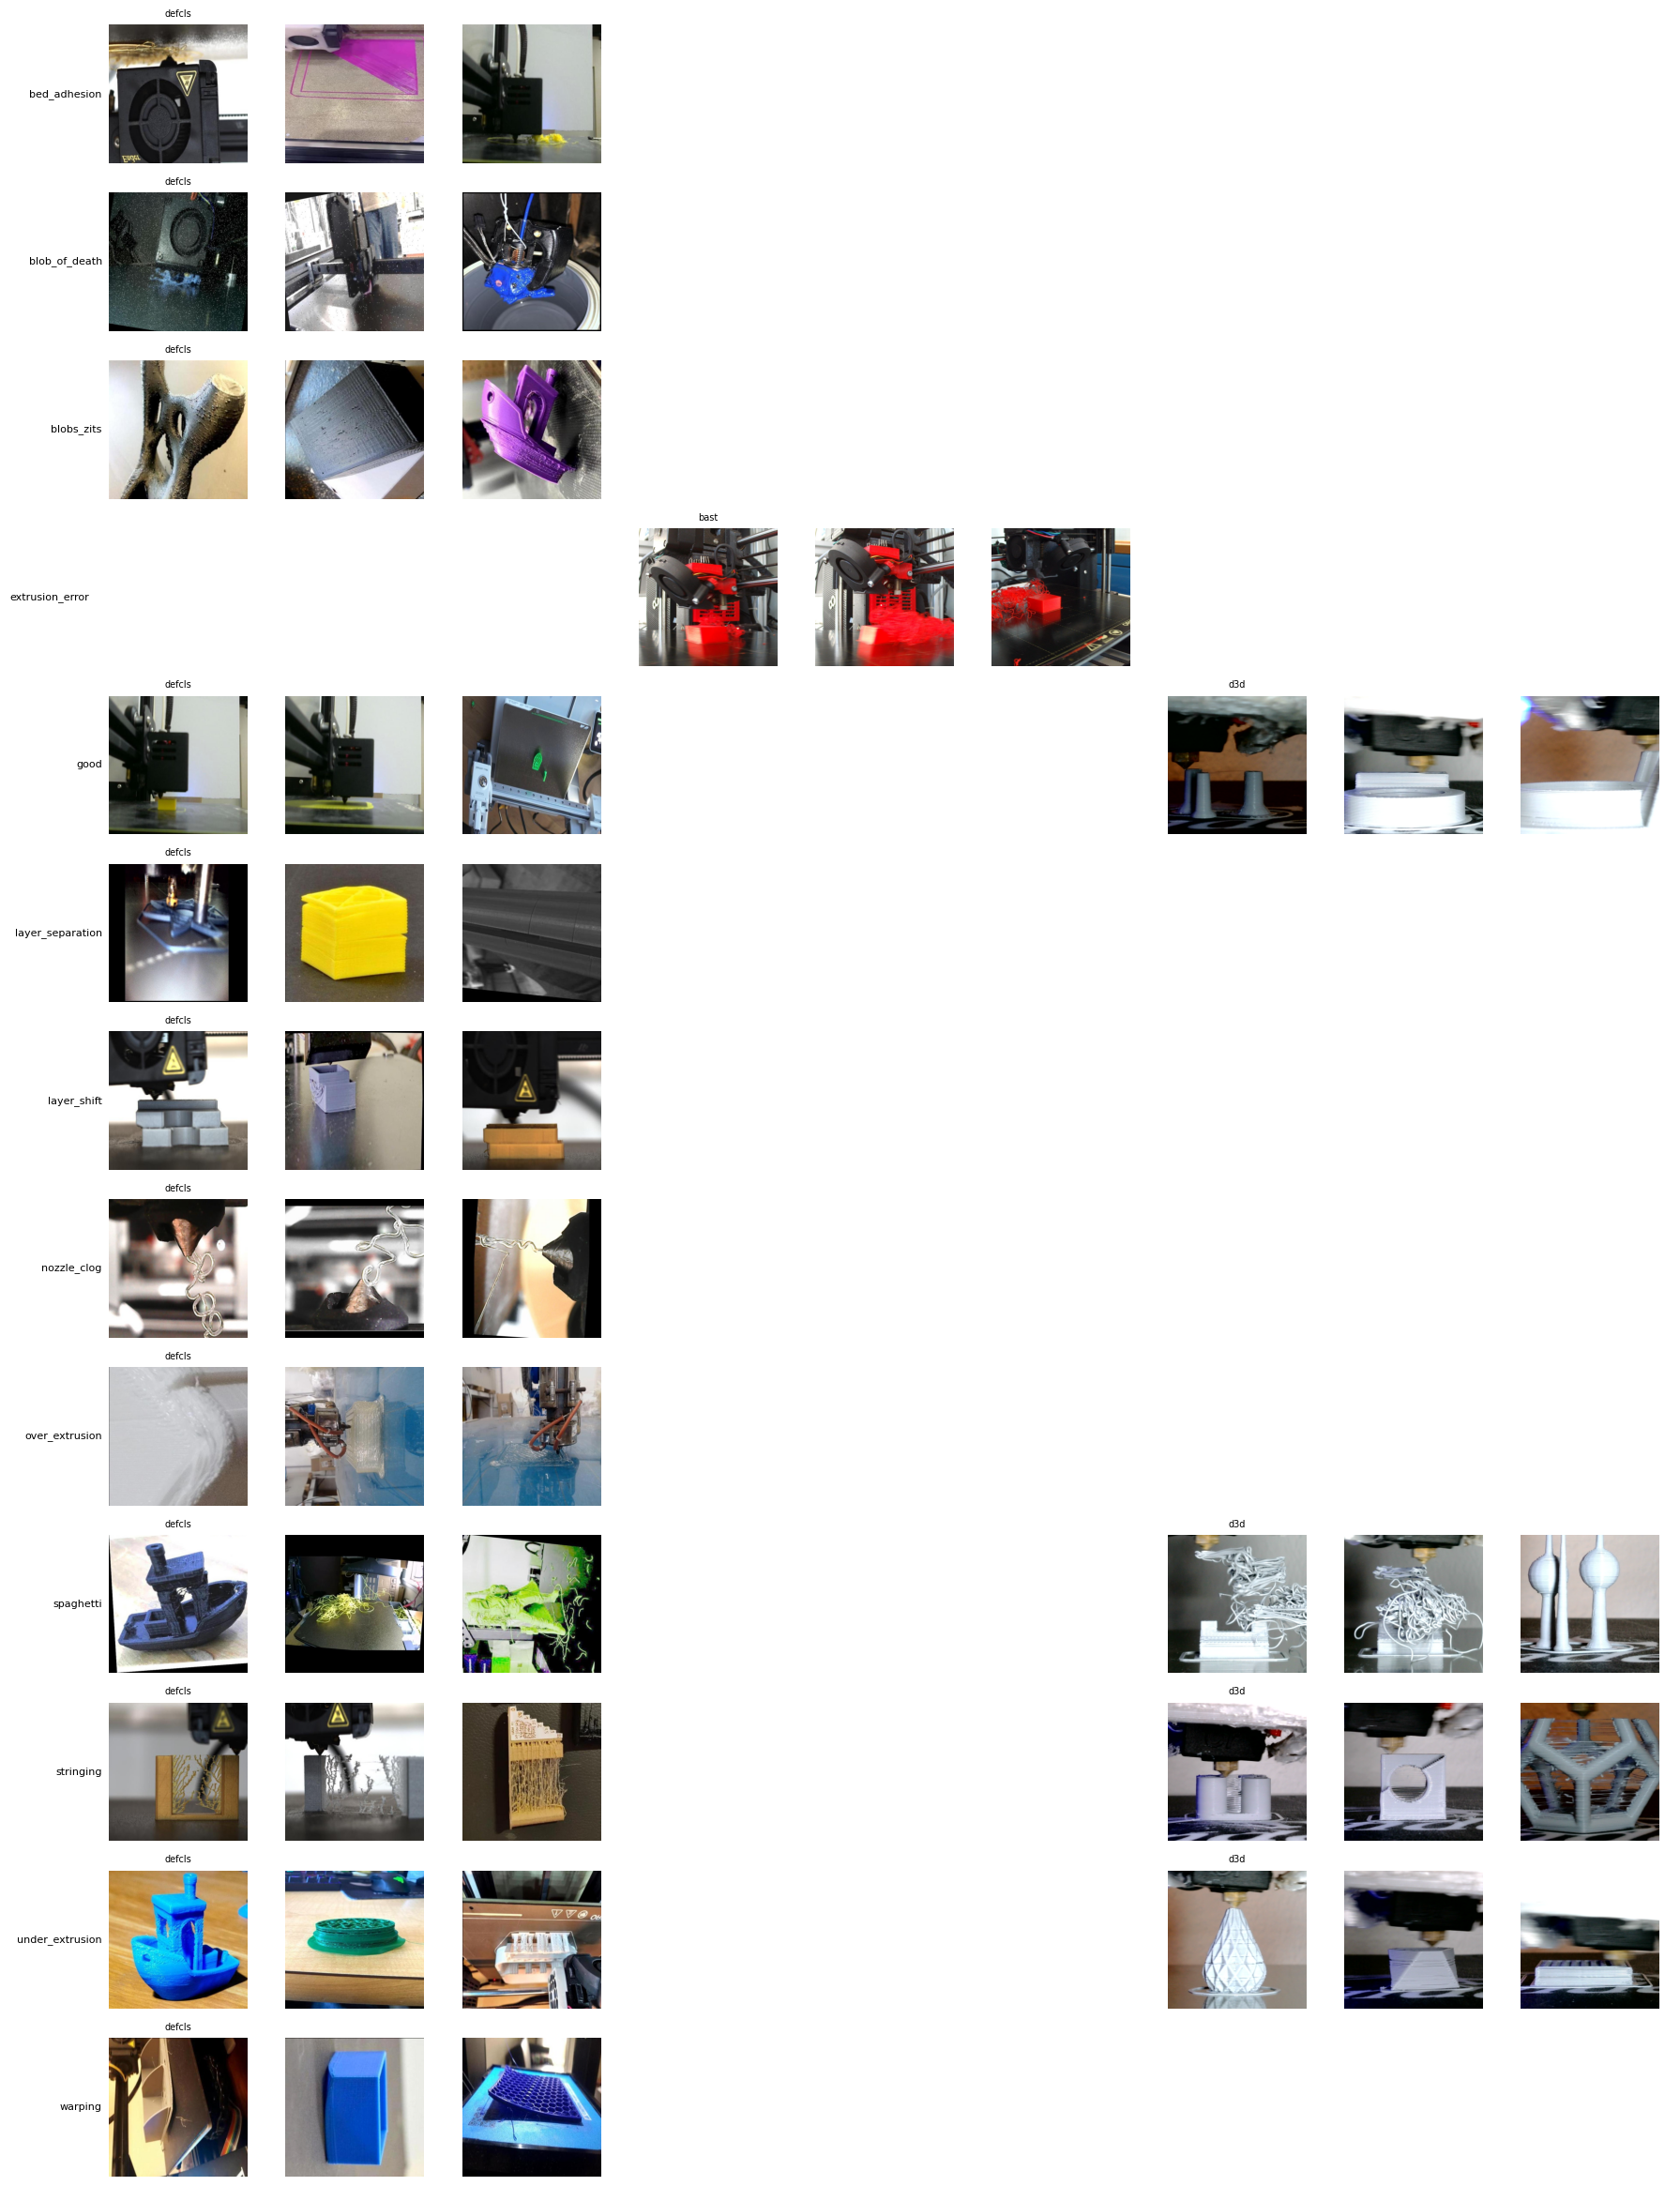

In [ ]:
import matplotlib.pyplot as plt

PER_DS = 3
classes = sorted(df['cls'].unique())
cols = PER_DS * len(DATASETS)
fig, axes = plt.subplots(len(classes), cols, figsize=(2.0 * cols, 1.8 * len(classes)), squeeze=False)
rnd = random.Random(0)
for r, c in enumerate(classes):
    for d, ds in enumerate(DATASETS):
        sub = df[(df['cls'] == c) & (df['dataset'] == ds)]
        picks = sub.sample(min(PER_DS, len(sub)), random_state=0)['path'].tolist() if len(sub) else []
        for k in range(PER_DS):
            ax = axes[r][d * PER_DS + k]
            ax.axis('off')
            if k < len(picks):
                ax.imshow(Image.open(picks[k]).convert('RGB'))
                if k == 0:
                    ax.set_title(f'{ds}', fontsize=7)
        if d == 0:
            axes[r][0].text(-0.05, 0.5, c, transform=axes[r][0].transAxes, ha='right', va='center', fontsize=8)
plt.tight_layout()
plt.show()

## Step 8: Split into train / val / test and save to Drive
- **train** (about 70 %): the model learns from these.
- **val** (about 15 %): used while training to compare settings.
- **test** (about 15 %): used once at the end to report accuracy.

Photos from the same group (same original photo and its augmented copies) always go to the same split. Bast `test_data` images always go to test, and Bast `base_data` images never go to test. It prints a table of images per class, warns about classes that are too small, and saves `merged_dataset.zip` and `merged_split.csv` in your Drive (the training notebook reads the zip; the csv records which image went where, so accuracy per dataset can be checked).

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)
folds = [te for _, te in sgkf.split(df, df['cls'], df['group'])]
df['split'] = 'train'
df.loc[folds[1], 'split'] = 'val'
df.loc[folds[0], 'split'] = 'test'

fixed_test = pd.Series(False, index=df.index)
is_authors_ds = df['dataset'].isin(list(AUTHORS_TEST_PREFIX))
for ds, prefix in AUTHORS_TEST_PREFIX.items():
    fixed_test |= (df['dataset'] == ds) & df['src'].str.lower().str.startswith(prefix.lower())
df.loc[fixed_test, 'split'] = 'test'                                   # the authors' own test images
df.loc[is_authors_ds & ~fixed_test & (df['split'] == 'test'), 'split'] = 'train'   # Bast base images never go to test

# Kaggle (d3d): the oblique/silver folders are the authors' held-out test sets.
# Route by group so a recording never splits across train and test.
d3d = df[df['dataset'] == 'd3d']
d3d_test_groups = set(d3d.loc[d3d['src'].str.contains(D3D_TEST_FOLDER_SUBSTR, case=False, na=False), 'group'])
if d3d_test_groups:
    df.loc[df['group'].isin(d3d_test_groups), 'split'] = 'test'
    pool = (df['dataset'] == 'd3d') & ~df['group'].isin(d3d_test_groups) & (df['split'] == 'test')
    df.loc[pool, 'split'] = 'train'                                    # d3d all_images never go to test
    print(f'd3d: {int(df["group"].isin(d3d_test_groups).sum())} oblique/silver images -> test split')

if OUT.exists():
    shutil.rmtree(OUT)
for r in df.itertuples():
    dst = OUT / r.split / r.cls / Path(r.path).name
    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(r.path, dst)

table = df.pivot_table(index='cls', columns='split', values='path', aggfunc='count', fill_value=0)
table = table.reindex(columns=['train', 'val', 'test'], fill_value=0)
table['total'] = table.sum(axis=1)
print(table)
print('\nImages per dataset and class:')
print(df.groupby(['dataset', 'cls']).size().unstack(fill_value=0).T)

print()
for c, row in table.iterrows():
    if row['total'] < 50:
        print(f'WARNING: class {c!r} has only {row["total"]} images. Consider merging it or leaving it out.')
    if row['val'] == 0 or row['test'] == 0:
        print(f'WARNING: class {c!r} is missing from val or test, so its accuracy cannot be measured.')

df.assign(file=df['path'].map(lambda s: Path(s).name)).drop(columns=['path', 'dhash']).to_csv(DRIVE / 'merged_split.csv', index=False)
print('\nZipping the merged dataset to Drive (can take a few minutes)...')
shutil.make_archive(str(DRIVE / 'merged_dataset'), 'zip', OUT)
print('Saved:', DRIVE / 'merged_dataset.zip')

split             train  val  test  total
cls                                      
bed_adhesion        722  132   129    983
blob_of_death       654  130   112    896
blobs_zits          708  148   142    998
extrusion_error     603   92   249    944
good                708  186   106   1000
layer_separation    641  128   126    895
layer_shift         694  137   140    971
nozzle_clog         716  142   138    996
over_extrusion      611  119   121    851
spaghetti           752  111   137   1000
stringing           780  108   112   1000
under_extrusion     700  114   186   1000
warping             671  129   133    933

Images per dataset and class:
dataset           bast  d3d  defcls
cls                                
bed_adhesion         0    0     983
blob_of_death        0    0     896
blobs_zits           0    0     998
extrusion_error    944    0       0
good                 0  881     119
layer_separation     0    0     895
layer_shift          0    0     971
nozzle_clog    

## Step 9: Folders for your own phone photos (accuracy check only)
This makes an empty folder for each class inside `defect_project/phone_test` in Drive. Later, put your phone photos of printed parts in the matching folders. They are **never used for training**, only to check the finished model.

In [ ]:
PHONE = DRIVE / 'phone_test'
for c in sorted(df['cls'].unique()):
    (PHONE / c).mkdir(parents=True, exist_ok=True)
print('Created:', PHONE)
print('Classes:', sorted(df['cls'].unique()))